In [ ]:
from google.colab import files
uploaded = files.upload()

Saving car data.csv to car data (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In this step, I imported all the necessary Python libraries required for the project. Pandas and NumPy are used for handling and analyzing data. Matplotlib and Seaborn are used for data visualization. Scikit-learn provides machine learning tools such as data splitting, preprocessing, model building, and evaluation metrics.

In [ ]:
df = pd.read_csv('car data.csv')
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


I loaded the car price dataset into a Pandas DataFrame. The head() function displays the first five records, which helps in understanding the structure and contents of the dataset

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


I examined the dataset information to understand the number of rows and columns, data types of each feature, and whether there are any missing values present in the dataset.

In [ ]:
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


This step checks for missing values in each column. Missing data can affect model performance, so it is important to identify and handle such values before training the machine learning model.

In [ ]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


I generated statistical information about the dataset, such as mean, minimum value, maximum value, and standard deviation. This provides a better understanding of the numerical features

In [ ]:
label_encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = label_encoder.fit_transform(df[col])

Machine learning models work with numerical data. Therefore, I converted categorical features such as car brand or fuel type into numerical values using Label Encoding

In [ ]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,90,2014,3.35,5.59,27000,2,0,1,0
1,93,2013,4.75,9.54,43000,1,0,1,0
2,68,2017,7.25,9.85,6900,2,0,1,0
3,96,2011,2.85,4.15,5200,2,0,1,0
4,92,2014,4.60,6.87,42450,1,0,1,0


In [ ]:
X = df.drop('Selling_Price', axis=1)
y = df['Selling_Price']

I separated the dataset into independent variables (features) and the dependent variable (target). The target variable is the selling price of the car, which the model will learn to predict.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

I divided the dataset into training and testing sets. The training data is used to train the model, while the testing data is used to evaluate its performance on unseen data.

In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

I trained a Random Forest Regression model using the training dataset. This algorithm creates multiple decision trees and combines their outputs to make more accurate predictions.

In [ ]:
y_pred = model.predict(X_test)

After training the model, I used it to predict car prices for the testing dataset. These predictions will be compared with actual prices to evaluate model performance.

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("R2 Score :", r2)

MAE : 0.589304918032787
MSE : 0.782636952131147
R2 Score : 0.9660248711535068


I evaluated the performance of the model using MAE, MSE, and R² Score. These metrics help determine how accurately the model predicts car prices.

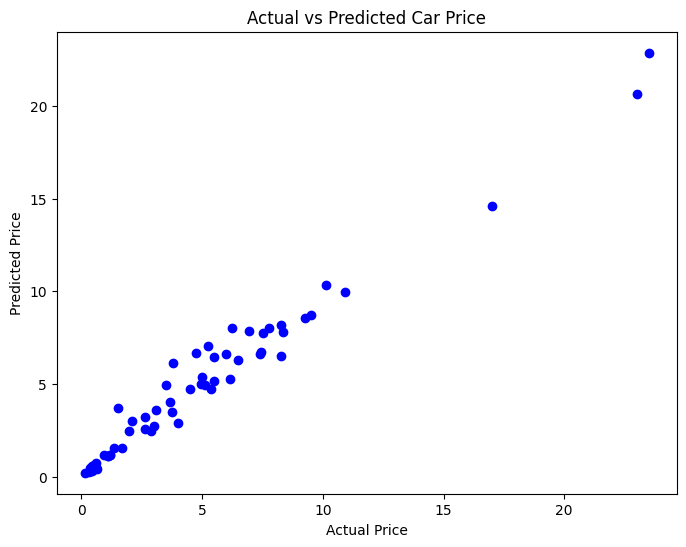

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, color='blue')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Car Price')
plt.show()

I created a scatter plot to compare actual car prices with predicted prices. If the points are close to the diagonal trend, it indicates good prediction accuracy.

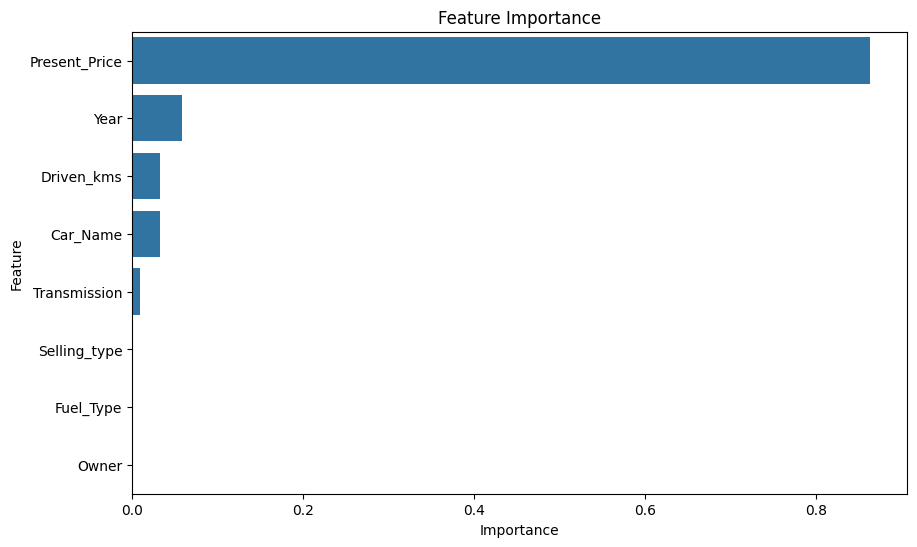

In [ ]:
importance = model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10,6))
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df
)

plt.title('Feature Importance')
plt.show()

I visualized feature importance using a bar chart. This chart clearly shows which car characteristics contribute most to price prediction.

In [ ]:
sample = X.iloc[[0]]

predicted_price = model.predict(sample)

print("Predicted Price =", predicted_price[0])

Predicted Price = 3.8885000000000036


Finally, I tested the trained model on a sample record from the dataset. The model successfully predicted a car price based on the provided features.